In [26]:
#próbka po plazmie tlenowo-argonowej 0 i 2 s

from funkcje.Lorentz2Raman import *

In [27]:
#import wszystkich mapek dla próbki 6

BASE = Path().resolve()
sciezka = BASE / "analiza" / "próbka6" / "dane_pomiarowe"

rs_PL_0s, I_PL_0s = importMap(sciezka/"WSe2_mapa_PL_6_0s.txt")
rs_PL_2s, I_PL_2s = importMap(sciezka/"WSe2_mapa_PL_6_2s.txt")


rs_Raman_0s, I_Raman_0s = importMap(sciezka/"WSe2_mapa_Raman_6_0s.txt")
rs_Raman_2s, I_Raman_2s = importMap(sciezka/"WSe2_mapa_Raman_6_2s.txt")



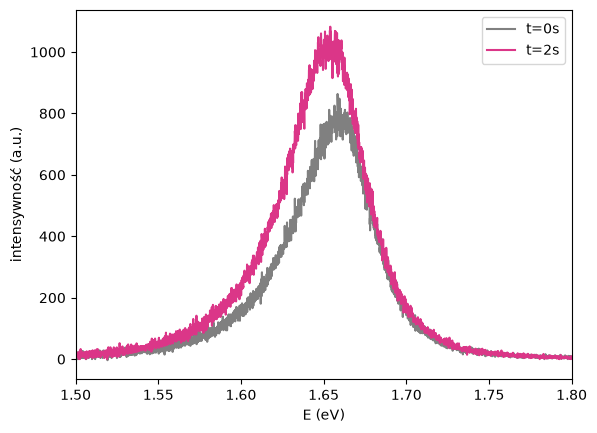

In [28]:
#testowe pojedyncze widma PL, żebym wiedziała co dopasować 

plt.plot(rs_PL_0s[10], I_PL_0s[10],label="t=0s",color='gray')
plt.plot(rs_PL_2s[10], I_PL_2s[10],label="t=2s",color="#DB3688")
plt.xlabel(r"E (eV)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
plt.xlim(1.5,1.8)

BASE = Path().resolve()
sciezka=BASE/"analiza"/"próbka6"/"wykresy"
plt.savefig(sciezka/'PL_2s.png')

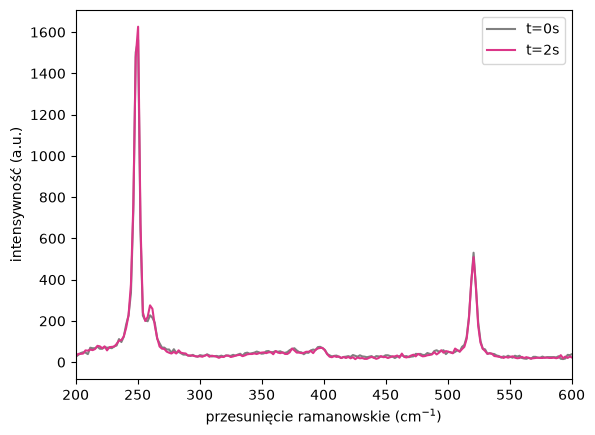

In [29]:
# testowe pojedyncze widma ramana, żebym wiedziała co dopasować 
plt.plot(rs_Raman_0s[10], I_Raman_0s[10],label="t=0s",color='gray')
plt.plot(rs_Raman_2s[10], I_Raman_2s[10],label="t=2s",color="#DB3688")
plt.xlabel(r"przesunięcie ramanowskie (cm$^{-1}$)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
plt.xlim(200,600)
plt.savefig(sciezka/'Raman_2s.png')

In [30]:
#dopasowanie piku PL

centers_PL_0s, fwhms_PL_0s, intensities_PL_0s = lorentz2map(rs_PL_0s, I_PL_0s, xmin=1.5, xmax=1.7)
centers_PL_2s, fwhms_PL_2s, intensities_PL_2s = lorentz2map(rs_PL_2s, I_PL_2s, xmin=1.55, xmax=1.75)

In [32]:
#dopasowanie piku E i A

centers_Raman_EA_0s, fwhms_Raman_EA_0s, intensities_Raman_EA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=240, xmax=255)
centers_Raman_EA_2s, fwhms_Raman_EA_2s, intensities_Raman_EA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=240, xmax=255)

In [33]:
#usunięcie punktów mocno odstających - krawędzi monowarswty/samego podłoża = dla widm ramaniowskich niepewnosc fwhm w granicach warstosci
maska_Raman_EA_0s=(fwhms_Raman_EA_0s>=0) &(fwhms_Raman_EA_0s<=20)
fwhms_Raman_EA_0s=fwhms_Raman_EA_0s[maska_Raman_EA_0s]
centers_Raman_EA_0s=centers_Raman_EA_0s[maska_Raman_EA_0s]
intensities_Raman_EA_0s=intensities_Raman_EA_0s[maska_Raman_EA_0s]

maska_Raman_EA_2s=(fwhms_Raman_EA_2s>=0) &(fwhms_Raman_EA_2s<=20)
fwhms_Raman_EA_2s=fwhms_Raman_EA_2s[maska_Raman_EA_2s]
centers_Raman_EA_2s=centers_Raman_EA_2s[maska_Raman_EA_2s]
intensities_Raman_EA_2s=intensities_Raman_EA_2s[maska_Raman_EA_2s]


In [34]:
#dopasowanie piku 2LA(M)

centers_Raman_LA_0s, fwhms_Raman_LA_0s, intensities_Raman_LA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=255, xmax=265)
centers_Raman_LA_2s, fwhms_Raman_LA_2s, intensities_Raman_LA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=255, xmax=265)

In [46]:
maska_Raman_LA_0s=(fwhms_Raman_LA_0s>=0) &(fwhms_Raman_LA_0s<=25)
fwhms_Raman_LA_0s=fwhms_Raman_LA_0s[maska_Raman_LA_0s]
centers_Raman_LA_0s=centers_Raman_LA_0s[maska_Raman_LA_0s]
intensities_Raman_LA_0s=intensities_Raman_LA_0s[maska_Raman_LA_0s]

maska_Raman_LA_2s=(fwhms_Raman_LA_2s>=0) &(fwhms_Raman_LA_2s<=25)
fwhms_Raman_LA_2s=fwhms_Raman_LA_2s[maska_Raman_LA_2s]
centers_Raman_LA_2s=centers_Raman_LA_2s[maska_Raman_LA_2s]
intensities_Raman_LA_2s=intensities_Raman_LA_2s[maska_Raman_LA_2s]

In [47]:
mu_centers_PL_0s, sigma_centers_PL_0s = norm.fit(centers_PL_0s)
print(f"{mu_centers_PL_0s} ± {sigma_centers_PL_0s}")
x_centers_PL_0s,y_centers_PL_0s=gauss(mu_centers_PL_0s,sigma_centers_PL_0s)

mu_centers_PL_2s, sigma_centers_PL_2s = norm.fit(centers_PL_2s)
print(f"{mu_centers_PL_2s} ± {sigma_centers_PL_2s}")
x_centers_PL_2s,y_centers_PL_2s=gauss(mu_centers_PL_2s,sigma_centers_PL_2s)

1.6563306830369786 ± 0.0017167206898688
1.6523979044540844 ± 0.0018886231005552478


In [48]:
mu_intensities_PL_0s, sigma_intensities_PL_0s = norm.fit(intensities_PL_0s)
print(f"{mu_intensities_PL_0s} ± {sigma_intensities_PL_0s}")
x_intensities_PL_0s,y_intensities_PL_0s=gauss(mu_intensities_PL_0s,sigma_intensities_PL_0s)


mu_intensities_PL_2s, sigma_intensities_PL_2s = norm.fit(intensities_PL_2s)
print(f"{mu_intensities_PL_2s} ± {sigma_intensities_PL_2s}")
x_intensities_PL_2s,y_intensities_PL_2s=gauss(mu_intensities_PL_2s,sigma_intensities_PL_2s)

1033.3191282960722 ± 282.97526719497665
1084.504862641363 ± 94.74084892487576


In [49]:
mu_fwhms_PL_0s, sigma_fwhms_PL_0s = norm.fit(fwhms_PL_0s)
print(f"{mu_fwhms_PL_0s} ± {sigma_fwhms_PL_0s}")
x_fwhms_PL_0s,y_fwhms_PL_0s=gauss(mu_fwhms_PL_0s,sigma_fwhms_PL_0s)


mu_fwhms_PL_2s, sigma_fwhms_PL_2s = norm.fit(fwhms_PL_2s)
print(f"{mu_fwhms_PL_2s} ± {sigma_fwhms_PL_2s}")
x_fwhms_PL_2s,y_fwhms_PL_2s=gauss(mu_fwhms_PL_2s,sigma_fwhms_PL_2s)

0.053613733587681955 ± 0.002486929033171074
0.052740749194427505 ± 0.0016039188775900679


In [50]:
mu_centers_Raman_EA_0s, sigma_centers_Raman_EA_0s = norm.fit(centers_Raman_EA_0s)
print(f"{mu_centers_Raman_EA_0s} ± {sigma_centers_Raman_EA_0s}")
x_centers_Raman_EA_0s,y_centers_Raman_EA_0s=gauss(mu_centers_Raman_EA_0s,sigma_centers_Raman_EA_0s)

mu_centers_Raman_EA_2s, sigma_centers_Raman_EA_2s = norm.fit(centers_Raman_EA_2s)
print(f"{mu_centers_Raman_EA_2s} ± {sigma_centers_Raman_EA_2s}")
x_centers_Raman_EA_2s,y_centers_Raman_EA_2s=gauss(mu_centers_Raman_EA_2s,sigma_centers_Raman_EA_2s)

249.4594220859671 ± 0.07602086403409729
249.45186798131974 ± 0.04913147964117928


In [51]:
mu_intensities_Raman_EA_0s, sigma_intensities_Raman_EA_0s = norm.fit(intensities_Raman_EA_0s)
print(f"{mu_intensities_Raman_EA_0s} ± {sigma_intensities_Raman_EA_0s}")
x_intensities_Raman_EA_0s,y_intensities_Raman_EA_0s=gauss(mu_intensities_Raman_EA_0s,sigma_intensities_Raman_EA_0s)

mu_intensities_Raman_EA_2s, sigma_intensities_Raman_EA_2s = norm.fit(intensities_Raman_EA_2s)
print(f"{mu_intensities_Raman_EA_2s} ± {sigma_intensities_Raman_EA_2s}")
x_intensities_Raman_EA_2s,y_intensities_Raman_EA_2s=gauss(mu_intensities_Raman_EA_2s,sigma_intensities_Raman_EA_2s)

1775.553870734501 ± 119.05978813656223
1778.430935730213 ± 53.38945666067336


In [52]:
mu_fwhms_Raman_EA_0s, sigma_fwhms_Raman_EA_0s = norm.fit(fwhms_Raman_EA_0s)
print(f"{mu_fwhms_Raman_EA_0s} ± {sigma_fwhms_Raman_EA_0s}")
x_fwhms_Raman_EA_0s,y_fwhms_Raman_EA_0s=gauss(mu_fwhms_Raman_EA_0s,sigma_fwhms_Raman_EA_0s)

mu_fwhms_Raman_EA_2s, sigma_fwhms_Raman_EA_2s = norm.fit(fwhms_Raman_EA_2s)
print(f"{mu_fwhms_Raman_EA_2s} ± {sigma_fwhms_Raman_EA_2s}")
x_fwhms_Raman_EA_2s,y_fwhms_Raman_EA_2s=gauss(mu_fwhms_Raman_EA_2s,sigma_fwhms_Raman_EA_2s)

4.556053705341344 ± 0.11033843157414161
4.660132396102459 ± 0.1181914108183603


In [53]:
mu_centers_Raman_LA_0s, sigma_centers_Raman_LA_0s = norm.fit(centers_Raman_LA_0s)
print(f"{mu_centers_Raman_LA_0s} ± {sigma_centers_Raman_LA_0s}")
x_centers_Raman_LA_0s,y_centers_Raman_LA_0s=gauss(mu_centers_Raman_LA_0s,sigma_centers_Raman_LA_0s)

mu_centers_Raman_LA_2s, sigma_centers_Raman_LA_2s = norm.fit(centers_Raman_LA_2s)
print(f"{mu_centers_Raman_LA_2s} ± {sigma_centers_Raman_LA_2s}")
x_centers_Raman_LA_2s,y_centers_Raman_LA_2s=gauss(mu_centers_Raman_LA_2s,sigma_centers_Raman_LA_2s)

260.15661378535754 ± 0.26159267794349644
260.0124668131607 ± 0.3520958504283625


In [54]:
mu_intensities_Raman_LA_0s, sigma_intensities_Raman_LA_0s = norm.fit(intensities_Raman_LA_0s)
print(f"{mu_intensities_Raman_LA_0s} ± {sigma_intensities_Raman_LA_0s}")
x_intensities_Raman_LA_0s,y_intensities_Raman_LA_0s=gauss(mu_intensities_Raman_LA_0s,sigma_intensities_Raman_LA_0s)

mu_intensities_Raman_LA_2s, sigma_intensities_Raman_LA_2s = norm.fit(intensities_Raman_LA_2s)
print(f"{mu_intensities_Raman_LA_2s} ± {sigma_intensities_Raman_LA_2s}")
x_intensities_Raman_LA_2s,y_intensities_Raman_LA_2s=gauss(mu_intensities_Raman_LA_2s,sigma_intensities_Raman_LA_2s)

239.7554038679635 ± 18.305100958313364
249.91257960399864 ± 11.782037276347758


In [55]:
mu_fwhms_Raman_LA_0s, sigma_fwhms_Raman_LA_0s = norm.fit(fwhms_Raman_LA_0s)
print(f"{mu_fwhms_Raman_LA_0s} ± {sigma_fwhms_Raman_LA_0s}")
x_fwhms_Raman_LA_0s,y_fwhms_Raman_LA_0s=gauss(mu_fwhms_Raman_LA_0s,sigma_fwhms_Raman_LA_0s)

mu_fwhms_Raman_LA_2s, sigma_fwhms_Raman_LA_2s = norm.fit(fwhms_Raman_LA_2s)
print(f"{mu_fwhms_Raman_LA_2s} ± {sigma_fwhms_Raman_LA_2s}")
x_fwhms_Raman_LA_2s,y_fwhms_Raman_LA_2s=gauss(mu_fwhms_Raman_LA_2s,sigma_fwhms_Raman_LA_2s)

16.306390967373257 ± 2.710481168542332
15.456424833508814 ± 2.979958524791191
